In [1]:
# ===============================================================
#  LIBRARIES, DATA LOADING AND TRAIN-TEST SPLIT
# ===============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import random
import matplotlib.pyplot as plt


# ===============================================================
# MODEL SELECTION
# ===============================================================

from sklearn.model_selection import (
    train_test_split,
    RepeatedStratifiedKFold,
    StratifiedKFold,
    cross_validate,
    learning_curve
)


# ===============================================================
# PREPROCESSING AND FEATURE SELECTION
# ===============================================================

from sklearn.preprocessing import StandardScaler

from sklearn.feature_selection import (
    SelectKBest,
    mutual_info_classif,
    RFE,
    SelectFromModel,
    f_classif
)


# ===============================================================
# IMBALANCED LEARNING
# ===============================================================

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE


# ===============================================================
# CLASSIFIERS
# ===============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier

from sklearn.ensemble import (
    VotingClassifier,
    StackingClassifier
)


# ===============================================================
# EVALUATION METRICS
# ===============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    brier_score_loss,
    precision_recall_curve,
    average_precision_score,
    roc_curve
)

from sklearn.calibration import calibration_curve
from statsmodels.stats.contingency_tables import mcnemar


# ===============================================================
# MODEL INTERPRETABILITY
# ===============================================================

import shap


# ===============================================================
# REPRODUCIBILITY
# ===============================================================

SEED = 42

np.random.seed(SEED)
random.seed(SEED)


# ===============================================================
# LOAD DATA
# ===============================================================

df = pd.read_excel(
    "Employee attrition dataset for non-tree-based models.xlsx"
)

print("Dataset Shape:", df.shape)



SECTOR_DUMMIES = [
    "Sector_Financial",
    "Sector_Food",
    "Sector_Medical",
    "Sector_Other"
]

DEPT_DUMMIES = [
    c for c in df.columns
    if c.startswith("Department_")
]


# ===============================================================
# VALIDATE REQUIRED COLUMNS
# ===============================================================

missing_sector_columns = [
    col for col in SECTOR_DUMMIES
    if col not in df.columns
]

if missing_sector_columns:
    raise ValueError(
        f"Missing sector columns: {missing_sector_columns}"
    )

if len(DEPT_DUMMIES) == 0:
    raise ValueError(
        "No department dummy columns were found."
    )


# ===============================================================
# LABEL RECONSTRUCTION FUNCTIONS
# ===============================================================

def reconstruct_sector(row):
    """Reconstruct the original sector label."""

    for col in SECTOR_DUMMIES:

        if row[col] == 1:
            return col.replace("Sector_", "")

    # Reference category
    return "Education"


def reconstruct_dept(row):
    """Reconstruct the original department label."""

    for col in DEPT_DUMMIES:

        if row[col] == 1:
            return col.replace("Department_", "")

    # Reference category
    return "Accounting"


# ===============================================================
# CREATE ANALYSIS-ONLY SUBGROUP LABELS
# ===============================================================

df["Sector_Label"] = (
    df[SECTOR_DUMMIES]
    .apply(reconstruct_sector, axis=1)
)

df["Dept_Label"] = (
    df[DEPT_DUMMIES]
    .apply(reconstruct_dept, axis=1)
)


# ===============================================================
# DISPLAY SUBGROUP DISTRIBUTIONS
# ===============================================================

print("\nSector Distribution:")
print(
    df["Sector_Label"]
    .value_counts()
    .to_string()
)

print("\nDepartment Distribution:")
print(
    df["Dept_Label"]
    .value_counts()
    .to_string()
)


# ===============================================================
# FEATURE MATRIX AND TARGET
# ---------------------------------------------------------------
# The target and analysis-only helper columns are excluded.
# ===============================================================

X = df.drop(
    columns=[
        "Attrition",
        "Sector_Label",
        "Dept_Label"
    ]
)

y = df["Attrition"]


# ===============================================================
# TRAIN-TEST SPLIT
# ===============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=SEED
)


# ===============================================================
# NUMBER OF FEATURES
# ===============================================================

n_features = X_train.shape[1]


# ===============================================================
# ALIGN SUBGROUP LABELS WITH THE TEST SET
# ---------------------------------------------------------------
# train_test_split shuffles observations. Therefore, subgroup
# labels must be aligned using the original DataFrame index.
# ===============================================================

sector_test = df.loc[
    X_test.index,
    "Sector_Label"
]

dept_test = df.loc[
    X_test.index,
    "Dept_Label"
]


# ===============================================================
# DATA SPLIT SUMMARY
# ===============================================================

print("\nTrain Shape:", X_train.shape)
print("Test Shape :", X_test.shape)

print("\nNumber of Predictive Features:", n_features)

print("\nTraining Target Distribution:")
print(
    y_train
    .value_counts()
    .to_string()
)

print("\nTest Target Distribution:")
print(
    y_test
    .value_counts()
    .to_string()
)


# ===============================================================
# VERIFY SUBGROUP LABELS
# ===============================================================

print(
    "\nSector Labels in Test Set:",
    sorted(sector_test.unique())
)

print(
    "Department Labels in Test Set:",
    sorted(dept_test.unique())
)

Dataset Shape: (1174, 44)

Sector Distribution:
Sector_Label
Other        343
Medical      298
Education    269
Financial    151
Food         113

Department Distribution:
Dept_Label
Other               219
Administration      190
Teaching            184
Patient Affairs     145
Customer Service    142
Sales               134
Processes            97
Accounting           63

Train Shape: (939, 43)
Test Shape : (235, 43)

Number of Predictive Features: 43

Training Target Distribution:
Attrition
0    541
1    398

Test Target Distribution:
Attrition
0    135
1    100

Sector Labels in Test Set: ['Education', 'Financial', 'Food', 'Medical', 'Other']
Department Labels in Test Set: ['Accounting', 'Administration', 'Customer Service', 'Other', 'Patient Affairs', 'Processes', 'Sales', 'Teaching']


In [2]:
# ===============================================================
# BASE MODELS
# ===============================================================
lr  = LogisticRegression(max_iter=3000, random_state=SEED)
svm = SVC(kernel="rbf", probability=True, random_state=SEED)
knn = KNeighborsClassifier(n_neighbors=5)
nb  = GaussianNB()
mlp = MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=1500, random_state=SEED)

# ===============================================================
# ENSEMBLES
# ===============================================================
voting = VotingClassifier(
    estimators=[("lr", lr), ("svm", svm), ("knn", knn), ("mlp", mlp)],
    voting="soft"
)

stacking = StackingClassifier(
    estimators=[("lr", lr), ("svm", svm), ("knn", knn), ("mlp", mlp)],
    final_estimator=LogisticRegression(),
    cv=5
)

models = {
    "Logistic Regression" : lr,
    "RBF_SVM"             : svm,
    "KNN"                 : knn,
    "Naive Bayes"         : nb,
    "MLP"                 : mlp,
    "Voting Ensemble"     : voting,
    "Stacking Ensemble"   : stacking
}

In [3]:
# ===============================================================
# FEATURE SELECTION METHODS
# ===============================================================

feature_selectors = {

    # -----------------------------------------------------------
    # ALL FEATURES
    # -----------------------------------------------------------
    
    "ALL": "passthrough",


    # -----------------------------------------------------------
    # ANOVA F-TEST
    # -----------------------------------------------------------

    "SelectKBest": SelectKBest(
        score_func=f_classif,
        k=min(20, n_features)
    ),


    # -----------------------------------------------------------
    # MUTUAL INFORMATION
    # -----------------------------------------------------------

    "MutualInformation": SelectKBest(
        score_func=mutual_info_classif,
        k=min(15, n_features)
    ),


    # -----------------------------------------------------------
    # RECURSIVE FEATURE ELIMINATION
    # -----------------------------------------------------------

    "RFE": RFE(
        estimator=LogisticRegression(
            max_iter=3000,
            random_state=SEED
        ),
        n_features_to_select=min(15, n_features)
    ),


    # -----------------------------------------------------------
    # L1-BASED FEATURE SELECTION
    # -----------------------------------------------------------

    "L1": SelectFromModel(
        LogisticRegression(
            penalty="l1",
            solver="liblinear",
            random_state=SEED
        )
    )
}

In [4]:
# ===============================================================
# LEAKAGE-SAFE NON-TREE PIPELINE
# ===============================================================
#
# Pipeline order:
#
# Training Fold
#      ↓
# StandardScaler
#      ↓
# Feature Selection
#      ↓
# SMOTE
#      ↓
# Classification Model
#
# During cross-validation, all preprocessing operations are fitted
# only on the training portion of each fold.
# ===============================================================

def make_pipeline(model, selector):

    pipeline = ImbPipeline(
        steps=[

            # ---------------------------------------------------
            # FEATURE SCALING
            # ---------------------------------------------------
            ("scaler", StandardScaler()),

            # ---------------------------------------------------
            # FEATURE SELECTION
            # Performed before SMOTE so that feature selection
            # is based on original training observations.
            # ---------------------------------------------------
            ("feature_selection", selector),

            # ---------------------------------------------------
            # SMOTE
            # Applied only during training within each CV fold.
            # ---------------------------------------------------
            ("smote", SMOTE(
                random_state=SEED
            )),

            # ---------------------------------------------------
            # CLASSIFICATION MODEL
            # ---------------------------------------------------
            ("model", model)
        ]
    )

    return pipeline


# ===============================================================
# PIPELINE VERIFICATION
# ===============================================================

print("NON-TREE MODEL PIPELINE")
print("=" * 65)

print("Step 1 : StandardScaler")
print("Step 2 : Feature Selection")
print("Step 3 : SMOTE")
print("Step 4 : Classification Model")

print("\n[OK] Leakage-safe non-tree pipeline is ready.")

NON-TREE MODEL PIPELINE
Step 1 : StandardScaler
Step 2 : Feature Selection
Step 3 : SMOTE
Step 4 : Classification Model

[OK] Leakage-safe non-tree pipeline is ready.


In [5]:
# ===============================================================
# REPEATED CROSS-VALIDATION — NON-TREE MODELS
# ===============================================================

# ---------------------------------------------------------------
# IMPORTANT:
# Use exactly the same CV configuration as the tree-model analysis.
# ---------------------------------------------------------------

cv_strategy = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=SEED
)


# ===============================================================
# SCORING METRICS
# ===============================================================

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}


# ===============================================================
# STORE RESULTS
# ===============================================================

results = []


# ===============================================================
# EVALUATE ALL FEATURE SET × MODEL COMBINATIONS
# ===============================================================

for feature_name, selector in feature_selectors.items():

    print("\n" + "=" * 70)
    print(f"FEATURE SET: {feature_name}")
    print("=" * 70)

    for model_name, model in models.items():

        print(f"Evaluating: {model_name} ...")

        # -------------------------------------------------------
        # Create leakage-safe pipeline
        # -------------------------------------------------------

        pipeline = make_pipeline(
            model=model,
            selector=selector
        )


        # -------------------------------------------------------
        # Repeated Cross-Validation
        # -------------------------------------------------------

        cv_results = cross_validate(
            estimator=pipeline,
            X=X_train,
            y=y_train,
            cv=cv_strategy,
            scoring=scoring,
            n_jobs=-1,
            return_train_score=False
        )


        # -------------------------------------------------------
        # Store Mean and Standard Deviation
        # -------------------------------------------------------

        results.append({

            "Feature_Set": feature_name,

            "Model": model_name,

            "CV Accuracy": np.mean(
                cv_results["test_accuracy"]
            ),

            "CV Accuracy SD": np.std(
                cv_results["test_accuracy"]
            ),

            "CV Precision": np.mean(
                cv_results["test_precision"]
            ),

            "CV Precision SD": np.std(
                cv_results["test_precision"]
            ),

            "CV Recall": np.mean(
                cv_results["test_recall"]
            ),

            "CV Recall SD": np.std(
                cv_results["test_recall"]
            ),

            "CV F1": np.mean(
                cv_results["test_f1"]
            ),

            "CV F1 SD": np.std(
                cv_results["test_f1"]
            ),

            "CV ROC_AUC": np.mean(
                cv_results["test_roc_auc"]
            ),

            "CV ROC_AUC SD": np.std(
                cv_results["test_roc_auc"]
            )
        })


# ===============================================================
# CREATE RESULTS DATAFRAME
# ===============================================================

results_df = pd.DataFrame(
    results
)


# ===============================================================
# SORT BY MEAN CV ROC-AUC
# ===============================================================

results_df = (
    results_df
    .sort_values(
        by="CV ROC_AUC",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)


# ===============================================================
# DISPLAY RESULTS
# ===============================================================

print("\n")
print("=" * 110)
print("FINAL NON-TREE MODEL COMPARISON — REPEATED CV (MEAN ± SD)")
print("=" * 110)

display_columns = [
    "Feature_Set",
    "Model",
    "CV Accuracy",
    "CV Accuracy SD",
    "CV Precision",
    "CV Precision SD",
    "CV Recall",
    "CV Recall SD",
    "CV F1",
    "CV F1 SD",
    "CV ROC_AUC",
    "CV ROC_AUC SD"
]

print(
    results_df[
        display_columns
    ]
)


FEATURE SET: ALL
Evaluating: Logistic Regression ...
Evaluating: RBF_SVM ...
Evaluating: KNN ...
Evaluating: Naive Bayes ...
Evaluating: MLP ...
Evaluating: Voting Ensemble ...
Evaluating: Stacking Ensemble ...

FEATURE SET: SelectKBest
Evaluating: Logistic Regression ...
Evaluating: RBF_SVM ...
Evaluating: KNN ...
Evaluating: Naive Bayes ...
Evaluating: MLP ...
Evaluating: Voting Ensemble ...
Evaluating: Stacking Ensemble ...

FEATURE SET: MutualInformation
Evaluating: Logistic Regression ...
Evaluating: RBF_SVM ...
Evaluating: KNN ...
Evaluating: Naive Bayes ...
Evaluating: MLP ...
Evaluating: Voting Ensemble ...
Evaluating: Stacking Ensemble ...

FEATURE SET: RFE
Evaluating: Logistic Regression ...
Evaluating: RBF_SVM ...
Evaluating: KNN ...
Evaluating: Naive Bayes ...
Evaluating: MLP ...
Evaluating: Voting Ensemble ...
Evaluating: Stacking Ensemble ...

FEATURE SET: L1
Evaluating: Logistic Regression ...
Evaluating: RBF_SVM ...
Evaluating: KNN ...
Evaluating: Naive Bayes ...
Evalu

In [6]:
# ===============================================================
# FORMATTED NON-TREE MODEL COMPARISON RESULTS
# ===============================================================

# ---------------------------------------------------------------
# Create a copy for formatted display
# ---------------------------------------------------------------

results_display = results_df.copy()


# ---------------------------------------------------------------
# Format Mean ± Standard Deviation
# ---------------------------------------------------------------

results_display["CV Accuracy"] = (
    results_display["CV Accuracy"]
    .map(lambda x: f"{x:.4f}")
    + " ± "
    + results_display["CV Accuracy SD"]
    .map(lambda x: f"{x:.4f}")
)

results_display["CV Precision"] = (
    results_display["CV Precision"]
    .map(lambda x: f"{x:.4f}")
    + " ± "
    + results_display["CV Precision SD"]
    .map(lambda x: f"{x:.4f}")
)

results_display["CV Recall"] = (
    results_display["CV Recall"]
    .map(lambda x: f"{x:.4f}")
    + " ± "
    + results_display["CV Recall SD"]
    .map(lambda x: f"{x:.4f}")
)

results_display["CV F1"] = (
    results_display["CV F1"]
    .map(lambda x: f"{x:.4f}")
    + " ± "
    + results_display["CV F1 SD"]
    .map(lambda x: f"{x:.4f}")
)

results_display["CV ROC_AUC"] = (
    results_display["CV ROC_AUC"]
    .map(lambda x: f"{x:.4f}")
    + " ± "
    + results_display["CV ROC_AUC SD"]
    .map(lambda x: f"{x:.4f}")
)


# ---------------------------------------------------------------
# Select columns for final display
# ---------------------------------------------------------------

final_cv_table = results_display[[
    "Feature_Set",
    "Model",
    "CV Accuracy",
    "CV Precision",
    "CV Recall",
    "CV F1",
    "CV ROC_AUC"
]]


# ===============================================================
# DISPLAY FINAL RESULTS
# ===============================================================

print("=" * 110)
print("FINAL NON-TREE MODEL COMPARISON — REPEATED CV (MEAN ± SD)")
print("=" * 110)

print(
    final_cv_table.to_string(
        index=False
    )
)


# ===============================================================
# DISPLAY BEST CONFIGURATION
# ===============================================================

best_cv_result = results_df.iloc[0]

print("\n" + "=" * 65)
print("BEST NON-TREE CONFIGURATION")
print("=" * 65)

print(
    "Feature Set :",
    best_cv_result["Feature_Set"]
)

print(
    "Model       :",
    best_cv_result["Model"]
)

print(
    f"\nCV ROC-AUC : "
    f"{best_cv_result['CV ROC_AUC']:.4f} "
    f"± "
    f"{best_cv_result['CV ROC_AUC SD']:.4f}"
)

FINAL NON-TREE MODEL COMPARISON — REPEATED CV (MEAN ± SD)
      Feature_Set               Model     CV Accuracy    CV Precision       CV Recall           CV F1      CV ROC_AUC
              RFE Logistic Regression 0.8328 ± 0.0199 0.8126 ± 0.0452 0.7915 ± 0.0238 0.8009 ± 0.0195 0.9177 ± 0.0153
              RFE   Stacking Ensemble 0.8367 ± 0.0205 0.8201 ± 0.0459 0.7924 ± 0.0299 0.8047 ± 0.0208 0.9170 ± 0.0158
               L1 Logistic Regression 0.8275 ± 0.0181 0.8088 ± 0.0473 0.7824 ± 0.0365 0.7937 ± 0.0186 0.9127 ± 0.0156
              ALL Logistic Regression 0.8257 ± 0.0194 0.8095 ± 0.0481 0.7756 ± 0.0363 0.7905 ± 0.0205 0.9120 ± 0.0158
              RFE     Voting Ensemble 0.8332 ± 0.0240 0.8116 ± 0.0478 0.7949 ± 0.0306 0.8019 ± 0.0242 0.9097 ± 0.0169
               L1   Stacking Ensemble 0.8218 ± 0.0222 0.8043 ± 0.0465 0.7714 ± 0.0353 0.7860 ± 0.0227 0.9081 ± 0.0160
              ALL   Stacking Ensemble 0.8200 ± 0.0245 0.7979 ± 0.0489 0.7764 ± 0.0299 0.7857 ± 0.0242 0.9073 ± 0.015

# ===============================================================
# FINAL NON-TREE MODEL TRAINING AND INDEPENDENT TEST EVALUATION
# ===============================================================

# ---------------------------------------------------------------
# SELECT BEST CONFIGURATION FROM SORTED RESULTS_DF
# ---------------------------------------------------------------

best_result = results_df.iloc[0]

best_feature_set = best_result["Feature_Set"]
best_model_name  = best_result["Model"]


# ---------------------------------------------------------------
# RETRIEVE MODEL AND FEATURE SELECTOR
# ---------------------------------------------------------------

best_model = models[
    best_model_name
]

best_selector = feature_selectors[
    best_feature_set
]


# ---------------------------------------------------------------
# CREATE FINAL PIPELINE
# ---------------------------------------------------------------

final_pipe = make_pipeline(
    model=best_model,
    selector=best_selector
)


# ===============================================================
# FINAL MODEL TRAINING
# ===============================================================

print("FINAL NON-TREE MODEL TRAINING")
print("=" * 65)

print("Selected Feature Set :", best_feature_set)
print("Selected Model       :", best_model_name)

final_pipe.fit(
    X_train,
    y_train
)

print(
    f"\n[OK] Final {best_model_name} pipeline "
    "trained on all training data."
)


# ===============================================================
# GENERATE TEST SET PROBABILITIES
# ===============================================================

y_prob = final_pipe.predict_proba(
    X_test
)[:, 1]


# ===============================================================
# OPERATING THRESHOLD
# ===============================================================

operating_threshold = 0.50

y_pred = (
    y_prob >= operating_threshold
).astype(int)

print("\nOperating Threshold:", operating_threshold)


# ===============================================================
# INDEPENDENT TEST PERFORMANCE
# ===============================================================

non_tree_test_results = {

    "Model": best_model_name,

    "Feature Set": best_feature_set,

    "Accuracy":
        accuracy_score(y_test, y_pred),

    "Precision":
        precision_score(y_test, y_pred),

    "Recall":
        recall_score(y_test, y_pred),

    "F1 Score":
        f1_score(y_test, y_pred),

    "ROC AUC":
        roc_auc_score(y_test, y_prob),

    "Brier Score":
        brier_score_loss(y_test, y_prob)
}


# ===============================================================
# DISPLAY RESULTS
# ===============================================================

print("\n" + "=" * 65)

print(
    f"INDEPENDENT TEST PERFORMANCE — "
    f"{best_model_name.upper()}"
)

print("=" * 65)

for metric, value in non_tree_test_results.items():

    if metric in ["Model", "Feature Set"]:
        print(f"{metric:<15}: {value}")

    else:
        print(f"{metric:<15}: {value:.4f}")


# ===============================================================
# CONFUSION MATRIX
# ===============================================================

non_tree_confusion_matrix = confusion_matrix(
    y_test,
    y_pred
)

print("\nCONFUSION MATRIX")
print("-" * 65)

print(non_tree_confusion_matrix)


# ===============================================================
# CLASSIFICATION REPORT
# ===============================================================

non_tree_classification_report = classification_report(
    y_test,
    y_pred,
    digits=4
)

print("\nCLASSIFICATION REPORT")
print("-" * 65)

print(non_tree_classification_report)

In [12]:
# ===============================================================
# FINAL NON-TREE MODEL TRAINING AND INDEPENDENT TEST EVALUATION
# ===============================================================

# ---------------------------------------------------------------
# SELECT BEST CONFIGURATION FROM SORTED RESULTS_DF
# ---------------------------------------------------------------

best_result = results_df.iloc[0]

best_feature_set = best_result["Feature_Set"]
best_model_name  = best_result["Model"]


# ---------------------------------------------------------------
# RETRIEVE MODEL AND FEATURE SELECTOR
# ---------------------------------------------------------------

best_model = models[
    best_model_name
]

best_selector = feature_selectors[
    best_feature_set
]


# ---------------------------------------------------------------
# CREATE FINAL PIPELINE
# ---------------------------------------------------------------

final_pipe = make_pipeline(
    model=best_model,
    selector=best_selector
)


# ===============================================================
# FINAL MODEL TRAINING
# ===============================================================

print("FINAL NON-TREE MODEL TRAINING")
print("=" * 65)

print("Selected Feature Set :", best_feature_set)
print("Selected Model       :", best_model_name)

final_pipe.fit(
    X_train,
    y_train
)

print(
    f"\n[OK] Final {best_model_name} pipeline "
    "trained on all training data."
)


# ===============================================================
# GENERATE TEST SET PROBABILITIES
# ===============================================================

y_prob = final_pipe.predict_proba(
    X_test
)[:, 1]


# ===============================================================
# OPERATING THRESHOLD
# ===============================================================

operating_threshold = 0.50

y_pred = (
    y_prob >= operating_threshold
).astype(int)

print("\nOperating Threshold:", operating_threshold)


# ===============================================================
# INDEPENDENT TEST PERFORMANCE
# ===============================================================

non_tree_test_results = {

    "Model": best_model_name,

    "Feature Set": best_feature_set,

    "Accuracy":
        accuracy_score(y_test, y_pred),

    "Precision":
        precision_score(y_test, y_pred),

    "Recall":
        recall_score(y_test, y_pred),

    "F1 Score":
        f1_score(y_test, y_pred),

    "ROC AUC":
        roc_auc_score(y_test, y_prob),

    "Brier Score":
        brier_score_loss(y_test, y_prob)
}


# ===============================================================
# DISPLAY RESULTS
# ===============================================================

print("\n" + "=" * 65)

print(
    f"INDEPENDENT TEST PERFORMANCE — "
    f"{best_model_name.upper()}"
)

print("=" * 65)

for metric, value in non_tree_test_results.items():

    if metric in ["Model", "Feature Set"]:
        print(f"{metric:<15}: {value}")

    else:
        print(f"{metric:<15}: {value:.4f}")


# ===============================================================
# CONFUSION MATRIX
# ===============================================================

non_tree_confusion_matrix = confusion_matrix(
    y_test,
    y_pred
)

print("\nCONFUSION MATRIX")
print("-" * 65)

print(non_tree_confusion_matrix)


# ===============================================================
# CLASSIFICATION REPORT
# ===============================================================

non_tree_classification_report = classification_report(
    y_test,
    y_pred,
    digits=4
)

print("\nCLASSIFICATION REPORT")
print("-" * 65)

print(non_tree_classification_report)

FINAL NON-TREE MODEL TRAINING
Selected Feature Set : RFE
Selected Model       : Logistic Regression

[OK] Final Logistic Regression pipeline trained on all training data.

Operating Threshold: 0.5

INDEPENDENT TEST PERFORMANCE — LOGISTIC REGRESSION
Model          : Logistic Regression
Feature Set    : RFE
Accuracy       : 0.7830
Precision      : 0.7692
Recall         : 0.7000
F1 Score       : 0.7330
ROC AUC        : 0.8735
Brier Score    : 0.1431

CONFUSION MATRIX
-----------------------------------------------------------------
[[114  21]
 [ 30  70]]

CLASSIFICATION REPORT
-----------------------------------------------------------------
              precision    recall  f1-score   support

           0     0.7917    0.8444    0.8172       135
           1     0.7692    0.7000    0.7330       100

    accuracy                         0.7830       235
   macro avg     0.7804    0.7722    0.7751       235
weighted avg     0.7821    0.7830    0.7814       235



In [13]:
# ===============================================================
# BOOTSTRAP 95% CONFIDENCE INTERVALS
# INDEPENDENT TEST SET — FINAL NON-TREE MODEL
# ===============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    brier_score_loss
)


# ---------------------------------------------------------------
# BOOTSTRAP SETTINGS
# ---------------------------------------------------------------

N_BOOTSTRAPS = 5000
RANDOM_STATE = 42

rng = np.random.default_rng(RANDOM_STATE)

y_true = np.asarray(y_test)
y_pred_arr = np.asarray(y_pred)
y_prob_arr = np.asarray(y_prob)

n_samples = len(y_true)


# ---------------------------------------------------------------
# METRIC STORAGE
# ---------------------------------------------------------------

bootstrap_results = {
    "Accuracy": [],
    "Precision": [],
    "Recall": [],
    "F1 Score": [],
    "ROC AUC": [],
    "Brier Score": []
}


# ---------------------------------------------------------------
# BOOTSTRAP SAMPLING
# ---------------------------------------------------------------

for _ in range(N_BOOTSTRAPS):

    # Sample indices with replacement
    indices = rng.integers(
        low=0,
        high=n_samples,
        size=n_samples
    )

    y_true_boot = y_true[indices]
    y_pred_boot = y_pred_arr[indices]
    y_prob_boot = y_prob_arr[indices]


    # Classification metrics
    bootstrap_results["Accuracy"].append(
        accuracy_score(y_true_boot, y_pred_boot)
    )

    bootstrap_results["Precision"].append(
        precision_score(
            y_true_boot,
            y_pred_boot,
            zero_division=0
        )
    )

    bootstrap_results["Recall"].append(
        recall_score(
            y_true_boot,
            y_pred_boot,
            zero_division=0
        )
    )

    bootstrap_results["F1 Score"].append(
        f1_score(
            y_true_boot,
            y_pred_boot,
            zero_division=0
        )
    )

    # ROC-AUC requires both classes to be present
    if len(np.unique(y_true_boot)) == 2:

        bootstrap_results["ROC AUC"].append(
            roc_auc_score(
                y_true_boot,
                y_prob_boot
            )
        )

    # Brier Score
    bootstrap_results["Brier Score"].append(
        brier_score_loss(
            y_true_boot,
            y_prob_boot
        )
    )


# ---------------------------------------------------------------
# CREATE 95% CONFIDENCE INTERVALS
# ---------------------------------------------------------------

ci_results = []

for metric, values in bootstrap_results.items():

    values = np.asarray(values)

    lower_ci = np.percentile(values, 2.5)
    upper_ci = np.percentile(values, 97.5)

    # Original estimate
    if metric == "Accuracy":
        point_estimate = accuracy_score(y_true, y_pred_arr)

    elif metric == "Precision":
        point_estimate = precision_score(
            y_true,
            y_pred_arr,
            zero_division=0
        )

    elif metric == "Recall":
        point_estimate = recall_score(
            y_true,
            y_pred_arr,
            zero_division=0
        )

    elif metric == "F1 Score":
        point_estimate = f1_score(
            y_true,
            y_pred_arr,
            zero_division=0
        )

    elif metric == "ROC AUC":
        point_estimate = roc_auc_score(
            y_true,
            y_prob_arr
        )

    elif metric == "Brier Score":
        point_estimate = brier_score_loss(
            y_true,
            y_prob_arr
        )

    ci_results.append({
        "Metric": metric,
        "Estimate": point_estimate,
        "95% CI Lower": lower_ci,
        "95% CI Upper": upper_ci,
        "95% CI": f"[{lower_ci:.4f}, {upper_ci:.4f}]"
    })


# ---------------------------------------------------------------
# DISPLAY RESULTS
# ---------------------------------------------------------------

non_tree_ci_results = pd.DataFrame(ci_results)

print(
    "\nBOOTSTRAP 95% CONFIDENCE INTERVALS — "
    "FINAL NON-TREE MODEL"
)

print("=" * 75)

print(
    non_tree_ci_results.to_string(
        index=False
    )
)


BOOTSTRAP 95% CONFIDENCE INTERVALS — FINAL NON-TREE MODEL
     Metric  Estimate  95% CI Lower  95% CI Upper           95% CI
   Accuracy  0.782979      0.727660      0.834043 [0.7277, 0.8340]
  Precision  0.769231      0.682353      0.852273 [0.6824, 0.8523]
     Recall  0.700000      0.603960      0.786410 [0.6040, 0.7864]
   F1 Score  0.732984      0.656246      0.800000 [0.6562, 0.8000]
    ROC AUC  0.873481      0.826956      0.914261 [0.8270, 0.9143]
Brier Score  0.143058      0.116365      0.172381 [0.1164, 0.1724]


In [14]:
# ===============================================================
# SAVE FINAL NON-TREE TEST PREDICTIONS
# FOR COMPARISON WITH TREE MODEL
# ===============================================================

import pandas as pd

non_tree_predictions_export = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "LR_Prediction": y_pred,
    "LR_Probability": y_prob
})

non_tree_predictions_export.to_csv(
    "non_tree_test_predictions.csv",
    index=False
)

print("[OK] Non-tree test predictions saved successfully.")

print("\nShape:", non_tree_predictions_export.shape)

display(non_tree_predictions_export.head())

[OK] Non-tree test predictions saved successfully.

Shape: (235, 3)


,Actual,LR_Prediction,LR_Probability
0,0,0,0.004496
1,1,0,0.044709
2,0,0,0.418621
3,0,0,0.095509
4,0,0,0.009144


In [15]:
import pandas as pd

non_tree_predictions_export = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "LR_Prediction": y_pred,
    "LR_Probability": y_prob
})

non_tree_predictions_export.to_csv(
    "non_tree_test_predictions.csv",
    index=False
)

print("[OK] Saved non_tree_test_predictions.csv")

[OK] Saved non_tree_test_predictions.csv


In [16]:
# ===============================================================
# LOAD LOGISTIC REGRESSION PREDICTIONS
# ===============================================================

import pandas as pd
import numpy as np

lr_predictions = pd.read_csv(
    "non_tree_test_predictions.csv"
)

print("[OK] Logistic Regression predictions loaded.")
print("Shape:", lr_predictions.shape)

display(lr_predictions.head())

[OK] Logistic Regression predictions loaded.
Shape: (235, 3)


,Actual,LR_Prediction,LR_Probability
0,0,0,0.004496
1,1,0,0.044709
2,0,0,0.418621
3,0,0,0.095509
4,0,0,0.009144


In [17]:
# ===============================================================
# VERIFY TEST SET ALIGNMENT
# ===============================================================

tree_actual = np.asarray(y_test)
lr_actual = lr_predictions["Actual"].to_numpy()

if np.array_equal(tree_actual, lr_actual):

    print(
        "[OK] Test observations are perfectly aligned."
    )

else:

    raise ValueError(
        "ERROR: The test observations are not aligned. "
        "Do not run McNemar's test until this is corrected."
    )

[OK] Test observations are perfectly aligned.


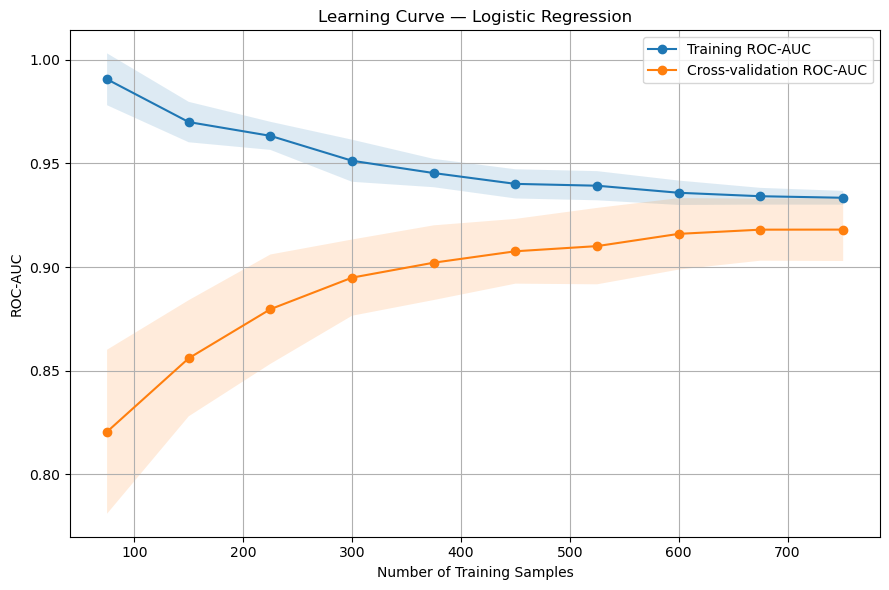

LEARNING CURVE SUMMARY
Final Training ROC-AUC   : 0.9334 ± 0.0033
Final CV ROC-AUC         : 0.9181 ± 0.0152

Training–Validation Gap  : 0.0154


In [18]:
# ===============================================================
# LEARNING CURVE — FINAL NON-TREE MODEL
# ===============================================================

# ---------------------------------------------------------------
# Use the same CV strategy as the main model evaluation
# ---------------------------------------------------------------

learning_cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=SEED
)


# ---------------------------------------------------------------
# Training set sizes
# ---------------------------------------------------------------

train_sizes = np.linspace(
    0.1,
    1.0,
    10
)


# ---------------------------------------------------------------
# Calculate learning curve
# ---------------------------------------------------------------

train_sizes_abs, train_scores, validation_scores = learning_curve(
    estimator=final_pipe,
    X=X_train,
    y=y_train,
    train_sizes=train_sizes,
    cv=learning_cv,
    scoring="roc_auc",
    n_jobs=-1,
    shuffle=True,
    random_state=SEED
)


# ---------------------------------------------------------------
# Calculate mean and standard deviation
# ---------------------------------------------------------------

train_mean = np.mean(
    train_scores,
    axis=1
)

train_std = np.std(
    train_scores,
    axis=1
)

validation_mean = np.mean(
    validation_scores,
    axis=1
)

validation_std = np.std(
    validation_scores,
    axis=1
)


# ===============================================================
# PLOT LEARNING CURVE
# ===============================================================

plt.figure(figsize=(9, 6))

plt.plot(
    train_sizes_abs,
    train_mean,
    marker="o",
    label="Training ROC-AUC"
)

plt.fill_between(
    train_sizes_abs,
    train_mean - train_std,
    train_mean + train_std,
    alpha=0.15
)


plt.plot(
    train_sizes_abs,
    validation_mean,
    marker="o",
    label="Cross-validation ROC-AUC"
)

plt.fill_between(
    train_sizes_abs,
    validation_mean - validation_std,
    validation_mean + validation_std,
    alpha=0.15
)


plt.xlabel("Number of Training Samples")
plt.ylabel("ROC-AUC")

plt.title(
    f"Learning Curve — {best_model_name}"
)

plt.legend()

plt.grid(True)

plt.tight_layout()
plt.savefig(
    "LC.png",
    dpi=600,
    bbox_inches="tight"
)
plt.show()


# ===============================================================
# FINAL LEARNING CURVE SUMMARY
# ===============================================================

print("LEARNING CURVE SUMMARY")
print("=" * 65)

print(
    f"Final Training ROC-AUC   : "
    f"{train_mean[-1]:.4f} ± {train_std[-1]:.4f}"
)

print(
    f"Final CV ROC-AUC         : "
    f"{validation_mean[-1]:.4f} ± "
    f"{validation_std[-1]:.4f}"
)

print(
    f"\nTraining–Validation Gap  : "
    f"{train_mean[-1] - validation_mean[-1]:.4f}"
)

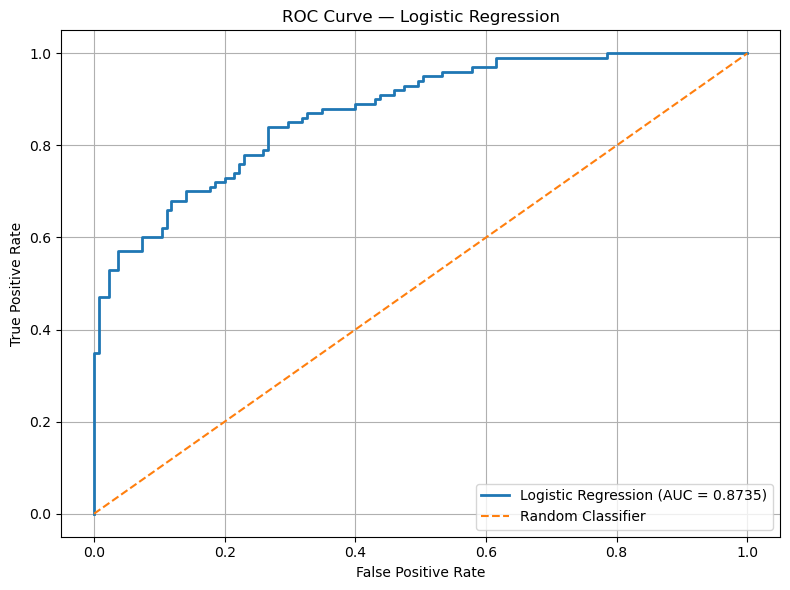

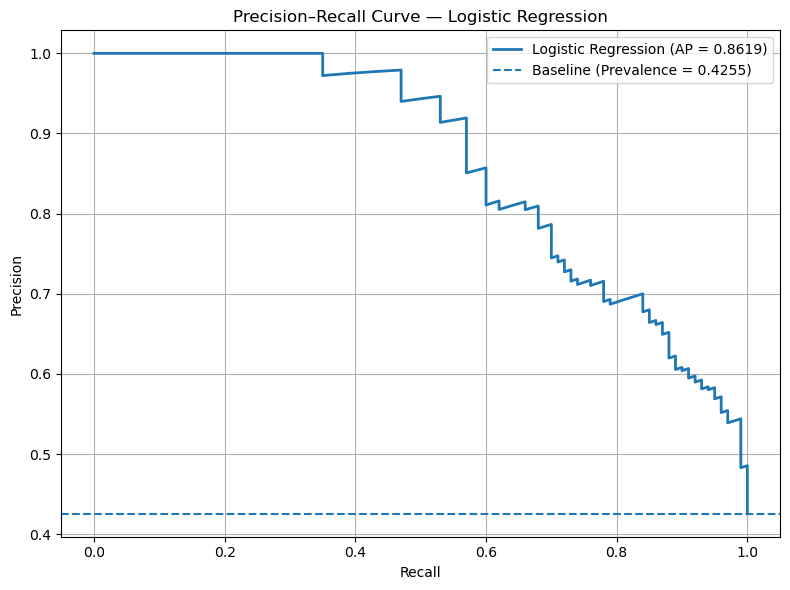

DISCRIMINATION PERFORMANCE — INDEPENDENT TEST SET
Model              : Logistic Regression
ROC-AUC            : 0.8735
Average Precision  : 0.8619


In [19]:
# ===============================================================
# ROC CURVE AND PRECISION–RECALL CURVE
# FINAL NON-TREE MODEL
# ===============================================================

# ---------------------------------------------------------------
# ROC CURVE VALUES
# ---------------------------------------------------------------

fpr, tpr, roc_thresholds = roc_curve(
    y_test,
    y_prob
)

test_roc_auc = roc_auc_score(
    y_test,
    y_prob
)


# ===============================================================
# PRECISION–RECALL CURVE VALUES
# ===============================================================

precision, recall, pr_thresholds = precision_recall_curve(
    y_test,
    y_prob
)

average_precision = average_precision_score(
    y_test,
    y_prob
)


# ===============================================================
# ROC CURVE PLOT
# ===============================================================

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"{best_model_name} (AUC = {test_roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    f"ROC Curve — {best_model_name}"
)

plt.legend(
    loc="lower right"
)

plt.grid(True)

plt.tight_layout()
plt.savefig(
    "ROC.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ===============================================================
# PRECISION–RECALL CURVE PLOT
# ===============================================================

plt.figure(figsize=(8, 6))

plt.plot(
    recall,
    precision,
    linewidth=2,
    label=(
        f"{best_model_name} "
        f"(AP = {average_precision:.4f})"
    )
)

# Baseline represents the positive-class prevalence
positive_prevalence = y_test.mean()

plt.axhline(
    y=positive_prevalence,
    linestyle="--",
    label=(
        f"Baseline "
        f"(Prevalence = {positive_prevalence:.4f})"
    )
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title(
    f"Precision–Recall Curve — {best_model_name}"
)

plt.legend()

plt.grid(True)

plt.tight_layout()
plt.savefig(
    "PR.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ===============================================================
# SUMMARY
# ===============================================================

print("DISCRIMINATION PERFORMANCE — INDEPENDENT TEST SET")
print("=" * 65)

print(f"Model              : {best_model_name}")
print(f"ROC-AUC            : {test_roc_auc:.4f}")
print(f"Average Precision  : {average_precision:.4f}")

TRAINING CALIBRATED MODELS
Training Platt-scaled model...
[OK] Platt scaling completed.

Training isotonic-calibrated model...
[OK] Isotonic calibration completed.


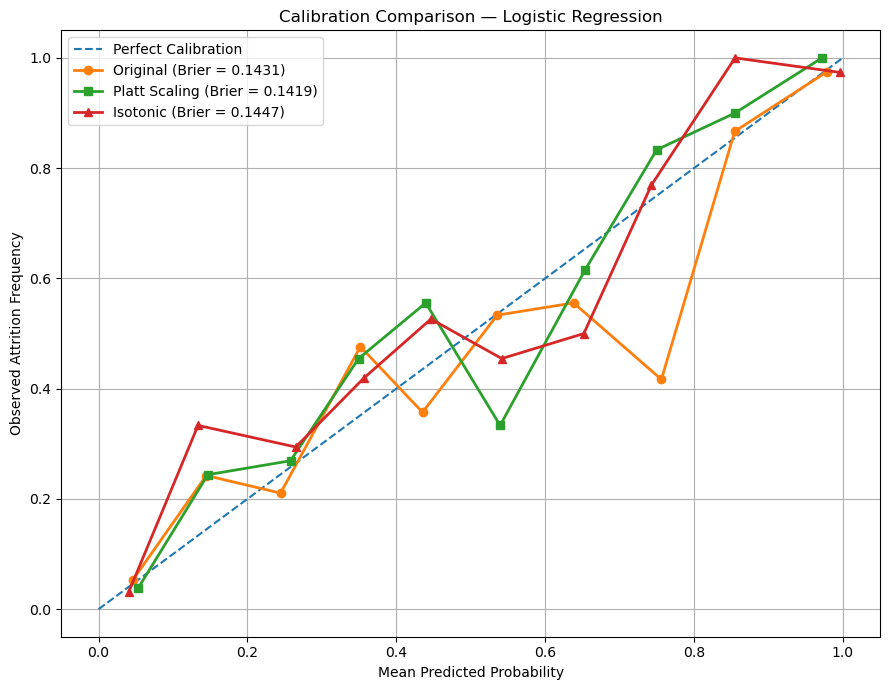


CALIBRATION COMPARISON — INDEPENDENT TEST SET
             Method  Brier Score  ROC-AUC
           Original       0.1431   0.8735
      Platt Scaling       0.1419   0.8747
Isotonic Regression       0.1447   0.8706


In [20]:
# ===============================================================
# CALIBRATION ANALYSIS — PLATT AND ISOTONIC
# ===============================================================

from sklearn.calibration import (
    CalibratedClassifierCV,
    calibration_curve
)


# ===============================================================
# CREATE TWO CALIBRATED MODELS
# ===============================================================

# ---------------------------------------------------------------
# PLATT SCALING (SIGMOID CALIBRATION)
# ---------------------------------------------------------------

platt_model = CalibratedClassifierCV(
    estimator=final_pipe,
    method="sigmoid",
    cv=5
)


# ---------------------------------------------------------------
# ISOTONIC REGRESSION CALIBRATION
# ---------------------------------------------------------------

isotonic_model = CalibratedClassifierCV(
    estimator=final_pipe,
    method="isotonic",
    cv=5
)


# ===============================================================
# TRAIN CALIBRATION MODELS
# ===============================================================

print("TRAINING CALIBRATED MODELS")
print("=" * 65)

print("Training Platt-scaled model...")

platt_model.fit(
    X_train,
    y_train
)

print("[OK] Platt scaling completed.")


print("\nTraining isotonic-calibrated model...")

isotonic_model.fit(
    X_train,
    y_train
)

print("[OK] Isotonic calibration completed.")


# ===============================================================
# GENERATE TEST SET PROBABILITIES
# ===============================================================

# Original model probabilities
y_prob_original = final_pipe.predict_proba(
    X_test
)[:, 1]


# Platt-scaled probabilities
y_prob_platt = platt_model.predict_proba(
    X_test
)[:, 1]


# Isotonic-calibrated probabilities
y_prob_isotonic = isotonic_model.predict_proba(
    X_test
)[:, 1]


# ===============================================================
# CALCULATE CALIBRATION CURVES
# ===============================================================

# Original
fraction_original, mean_predicted_original = calibration_curve(
    y_test,
    y_prob_original,
    n_bins=10,
    strategy="uniform"
)


# Platt
fraction_platt, mean_predicted_platt = calibration_curve(
    y_test,
    y_prob_platt,
    n_bins=10,
    strategy="uniform"
)


# Isotonic
fraction_isotonic, mean_predicted_isotonic = calibration_curve(
    y_test,
    y_prob_isotonic,
    n_bins=10,
    strategy="uniform"
)


# ===============================================================
# BRIER SCORES
# ===============================================================

brier_original = brier_score_loss(
    y_test,
    y_prob_original
)

brier_platt = brier_score_loss(
    y_test,
    y_prob_platt
)

brier_isotonic = brier_score_loss(
    y_test,
    y_prob_isotonic
)


# ===============================================================
# ROC-AUC AFTER CALIBRATION
# ===============================================================

roc_original = roc_auc_score(
    y_test,
    y_prob_original
)

roc_platt = roc_auc_score(
    y_test,
    y_prob_platt
)

roc_isotonic = roc_auc_score(
    y_test,
    y_prob_isotonic
)


# ===============================================================
# CALIBRATION CURVE COMPARISON
# ===============================================================

plt.figure(figsize=(9, 7))


# Perfect calibration line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)


# Original model
plt.plot(
    mean_predicted_original,
    fraction_original,
    marker="o",
    linewidth=2,
    label=(
        f"Original "
        f"(Brier = {brier_original:.4f})"
    )
)


# Platt scaling
plt.plot(
    mean_predicted_platt,
    fraction_platt,
    marker="s",
    linewidth=2,
    label=(
        f"Platt Scaling "
        f"(Brier = {brier_platt:.4f})"
    )
)


# Isotonic regression
plt.plot(
    mean_predicted_isotonic,
    fraction_isotonic,
    marker="^",
    linewidth=2,
    label=(
        f"Isotonic "
        f"(Brier = {brier_isotonic:.4f})"
    )
)


plt.xlabel("Mean Predicted Probability")

plt.ylabel("Observed Attrition Frequency")

plt.title(
    f"Calibration Comparison — {best_model_name}"
)

plt.legend()

plt.grid(True)

plt.tight_layout()
plt.savefig(
    "calib.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ===============================================================
# CALIBRATION RESULTS TABLE
# ===============================================================

calibration_results = pd.DataFrame({

    "Method": [
        "Original",
        "Platt Scaling",
        "Isotonic Regression"
    ],

    "Brier Score": [
        brier_original,
        brier_platt,
        brier_isotonic
    ],

    "ROC-AUC": [
        roc_original,
        roc_platt,
        roc_isotonic
    ]
})


print("\nCALIBRATION COMPARISON — INDEPENDENT TEST SET")
print("=" * 65)

print(
    calibration_results
    .round(4)
    .to_string(index=False)
)

In [21]:
# ===============================================================
# ERROR ANALYSIS — FINAL NON-TREE MODEL
# ===============================================================

# ---------------------------------------------------------------
# CREATE ERROR ANALYSIS DATAFRAME
# ---------------------------------------------------------------

error_analysis_df = X_test.copy()

error_analysis_df["Actual"] = y_test
error_analysis_df["Predicted"] = y_pred
error_analysis_df["Predicted_Probability"] = y_prob


# ---------------------------------------------------------------
# ADD ERROR CATEGORY
# ---------------------------------------------------------------

def classify_prediction_error(row):

    if row["Actual"] == 1 and row["Predicted"] == 1:
        return "True Positive"

    elif row["Actual"] == 0 and row["Predicted"] == 0:
        return "True Negative"

    elif row["Actual"] == 0 and row["Predicted"] == 1:
        return "False Positive"

    else:
        return "False Negative"


error_analysis_df["Prediction_Category"] = (
    error_analysis_df
    .apply(
        classify_prediction_error,
        axis=1
    )
)


# ===============================================================
# ADD SUBGROUP LABELS
# ===============================================================

error_analysis_df["Sector"] = sector_test
error_analysis_df["Department"] = dept_test


# ===============================================================
# ERROR CATEGORY COUNTS
# ===============================================================

error_counts = (
    error_analysis_df["Prediction_Category"]
    .value_counts()
)


print("=" * 65)
print("ERROR ANALYSIS — FINAL NON-TREE MODEL")
print("=" * 65)

print(f"Model         : {best_model_name}")
print(f"Feature Set   : {best_feature_set}")
print(f"Threshold     : {operating_threshold}")

print("\nPrediction Category Counts:")
print(
    error_counts
    .reindex([
        "True Positive",
        "True Negative",
        "False Positive",
        "False Negative"
    ])
    .fillna(0)
    .astype(int)
)


# ===============================================================
# ERROR SUMMARY
# ===============================================================

total_test_samples = len(error_analysis_df)

false_positive_count = (
    error_analysis_df["Prediction_Category"]
    .eq("False Positive")
    .sum()
)

false_negative_count = (
    error_analysis_df["Prediction_Category"]
    .eq("False Negative")
    .sum()
)


print("\nERROR SUMMARY")
print("-" * 65)

print(
    f"Total Test Samples : {total_test_samples}"
)

print(
    f"False Positives    : {false_positive_count}"
)

print(
    f"False Negatives    : {false_negative_count}"
)

print(
    f"Total Errors       : "
    f"{false_positive_count + false_negative_count}"
)

print(
    f"Error Rate         : "
    f"{(false_positive_count + false_negative_count) / total_test_samples:.4f}"
)


# ===============================================================
# MOST CONFIDENT FALSE POSITIVES
# ===============================================================
# These employees were predicted as likely to leave with a high
# probability, but they actually did not leave.
# ===============================================================

most_confident_fp = (
    error_analysis_df[
        error_analysis_df["Prediction_Category"]
        == "False Positive"
    ]
    .sort_values(
        by="Predicted_Probability",
        ascending=False
    )
)


print("\n" + "=" * 65)
print("MOST CONFIDENT FALSE POSITIVES")
print("=" * 65)

print(
    most_confident_fp[
        [
            "Actual",
            "Predicted",
            "Predicted_Probability",
            "Sector",
            "Department"
        ]
    ]
    .head(10)
    .to_string()
)


# ===============================================================
# MOST CONFIDENT FALSE NEGATIVES
# ===============================================================
# These employees actually left, but the model predicted that they
# would remain.
# ===============================================================

most_confident_fn = (
    error_analysis_df[
        error_analysis_df["Prediction_Category"]
        == "False Negative"
    ]
    .sort_values(
        by="Predicted_Probability",
        ascending=True
    )
)


print("\n" + "=" * 65)
print("MOST CONFIDENT FALSE NEGATIVES")
print("=" * 65)

print(
    most_confident_fn[
        [
            "Actual",
            "Predicted",
            "Predicted_Probability",
            "Sector",
            "Department"
        ]
    ]
    .head(10)
    .to_string()
)


# ===============================================================
# ERROR DISTRIBUTION BY SECTOR
# ===============================================================

sector_error_analysis = pd.crosstab(
    error_analysis_df["Sector"],
    error_analysis_df["Prediction_Category"]
)


print("\n" + "=" * 65)
print("ERROR DISTRIBUTION BY SECTOR")
print("=" * 65)

print(sector_error_analysis)


# ===============================================================
# ERROR DISTRIBUTION BY DEPARTMENT
# ===============================================================

department_error_analysis = pd.crosstab(
    error_analysis_df["Department"],
    error_analysis_df["Prediction_Category"]
)


print("\n" + "=" * 65)
print("ERROR DISTRIBUTION BY DEPARTMENT")
print("=" * 65)

print(department_error_analysis)

ERROR ANALYSIS — FINAL NON-TREE MODEL
Model         : Logistic Regression
Feature Set   : RFE
Threshold     : 0.5

Prediction Category Counts:
Prediction_Category
True Positive      70
True Negative     114
False Positive     21
False Negative     30
Name: count, dtype: int64

ERROR SUMMARY
-----------------------------------------------------------------
Total Test Samples : 235
False Positives    : 21
False Negatives    : 30
Total Errors       : 51
Error Rate         : 0.2170

MOST CONFIDENT FALSE POSITIVES
     Actual  Predicted  Predicted_Probability     Sector        Department
138       0          1               0.946570    Medical             Other
859       0          1               0.842092      Other  Customer Service
997       0          1               0.841070       Food             Sales
70        0          1               0.786780  Financial  Customer Service
228       0          1               0.781510    Medical   Patient Affairs
299       0          1             

In [22]:
# ===============================================================
# FULL DATASET SUBGROUP DISTRIBUTION
# ===============================================================

sector_distribution = pd.DataFrame({

    "Sector":
        df["Sector_Label"].value_counts().index,

    "Sample Size":
        df["Sector_Label"].value_counts().values
})


department_distribution = pd.DataFrame({

    "Department":
        df["Dept_Label"].value_counts().index,

    "Sample Size":
        df["Dept_Label"].value_counts().values
})


print("SECTOR DISTRIBUTION")
print("=" * 65)

print(
    sector_distribution
    .sort_values("Sample Size", ascending=False)
    .to_string(index=False)
)


print("\nDEPARTMENT DISTRIBUTION")
print("=" * 65)

print(
    department_distribution
    .sort_values("Sample Size", ascending=False)
    .to_string(index=False)
)

SECTOR DISTRIBUTION
   Sector  Sample Size
    Other          343
  Medical          298
Education          269
Financial          151
     Food          113

DEPARTMENT DISTRIBUTION
      Department  Sample Size
           Other          219
  Administration          190
        Teaching          184
 Patient Affairs          145
Customer Service          142
           Sales          134
       Processes           97
      Accounting           63


In [23]:

# ===============================================================
# SUBGROUP ANALYSIS — NON-TREE FINAL MODEL
# Sector and Department
# ===============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)


# ===============================================================
# MINIMUM SUBGROUP SIZE RULES
# ===============================================================

# Minimum total observations in a subgroup
MIN_SUBGROUP_SIZE = 20

# Minimum observations required in each class
MIN_CLASS_SIZE = 5


# ===============================================================
# BOOTSTRAP SETTINGS
# ===============================================================

N_BOOTSTRAPS = 1000


# ===============================================================
# BOOTSTRAP ROC-AUC CONFIDENCE INTERVAL
# ===============================================================

def bootstrap_auc_ci(
    y_true,
    y_probability,
    n_bootstraps=N_BOOTSTRAPS,
    random_state=SEED
):

    rng = np.random.RandomState(random_state)

    y_true = np.asarray(y_true)
    y_probability = np.asarray(y_probability)

    bootstrap_scores = []

    for _ in range(n_bootstraps):

        indices = rng.randint(
            0,
            len(y_true),
            len(y_true)
        )

        y_boot = y_true[indices]
        prob_boot = y_probability[indices]

        # ROC-AUC cannot be computed if only one class
        # appears in the bootstrap sample
        if len(np.unique(y_boot)) < 2:
            continue

        score = roc_auc_score(
            y_boot,
            prob_boot
        )

        bootstrap_scores.append(score)


    # -----------------------------------------------------------
    # Return 95% confidence interval
    # -----------------------------------------------------------

    if len(bootstrap_scores) == 0:
        return np.nan, np.nan

    lower = np.percentile(
        bootstrap_scores,
        2.5
    )

    upper = np.percentile(
        bootstrap_scores,
        97.5
    )

    return lower, upper


# ===============================================================
# SUBGROUP PERFORMANCE FUNCTION
# ===============================================================

def subgroup_analysis(
    subgroup_labels,
    subgroup_name,
    y_true,
    y_predicted,
    y_probability,
    min_size=MIN_SUBGROUP_SIZE,
    min_class_size=MIN_CLASS_SIZE
):

    results = []


    # -----------------------------------------------------------
    # Ensure index alignment
    # -----------------------------------------------------------

    subgroup_labels = pd.Series(
        subgroup_labels,
        index=y_true.index
    )


    # -----------------------------------------------------------
    # Analyse each subgroup
    # -----------------------------------------------------------

    for group in sorted(
        subgroup_labels.dropna().unique()
    ):

        # -------------------------------------------------------
        # Create subgroup mask
        # -------------------------------------------------------

        mask = (
            subgroup_labels == group
        )


        # -------------------------------------------------------
        # Extract subgroup observations
        # -------------------------------------------------------

        y_group = y_true.loc[mask]

        y_pred_group = np.asarray(
            y_predicted
        )[mask.to_numpy()]

        y_prob_group = np.asarray(
            y_probability
        )[mask.to_numpy()]


        # -------------------------------------------------------
        # Subgroup size and class distribution
        # -------------------------------------------------------

        n = len(
            y_group
        )

        positives = int(
            y_group.sum()
        )

        negatives = int(
            n - positives
        )


        # =======================================================
        # SUBGROUP ELIGIBILITY RULE
        #
        # 1. Minimum total subgroup size
        # 2. Minimum observations in each class
        # =======================================================

        sufficient_data = (

            n >= min_size

            and

            positives >= min_class_size

            and

            negatives >= min_class_size
        )


        # -------------------------------------------------------
        # Insufficient subgroup
        # -------------------------------------------------------

        if not sufficient_data:

            results.append({

                subgroup_name: group,

                "N": n,

                "Attrition Cases": positives,

                "Non-Attrition Cases": negatives,

                "Eligible": "No",

                "Accuracy": np.nan,

                "Precision": np.nan,

                "Recall": np.nan,

                "F1 Score": np.nan,

                "ROC AUC": np.nan,

                "ROC AUC 95% CI":
                    "Not estimated"

            })

            continue


        # =======================================================
        # CLASSIFICATION METRICS
        # =======================================================

        accuracy = accuracy_score(
            y_group,
            y_pred_group
        )


        precision = precision_score(
            y_group,
            y_pred_group,
            zero_division=0
        )


        recall = recall_score(
            y_group,
            y_pred_group,
            zero_division=0
        )


        f1 = f1_score(
            y_group,
            y_pred_group,
            zero_division=0
        )


        # =======================================================
        # ROC-AUC AND 95% BOOTSTRAP CI
        # =======================================================

        roc_auc = roc_auc_score(
            y_group,
            y_prob_group
        )


        ci_lower, ci_upper = bootstrap_auc_ci(
            y_group,
            y_prob_group,
            random_state=SEED
        )


        auc_ci = (
            f"[{ci_lower:.3f}, "
            f"{ci_upper:.3f}]"
        )


        # =======================================================
        # STORE RESULTS
        # =======================================================

        results.append({

            subgroup_name: group,

            "N": n,

            "Attrition Cases": positives,

            "Non-Attrition Cases": negatives,

            "Eligible": "Yes",

            "Accuracy": accuracy,

            "Precision": precision,

            "Recall": recall,

            "F1 Score": f1,

            "ROC AUC": roc_auc,

            "ROC AUC 95% CI": auc_ci

        })


    return pd.DataFrame(
        results
    )


# ===============================================================
# SECTOR ANALYSIS
# ===============================================================

sector_results_non_tree = subgroup_analysis(

    subgroup_labels=sector_test,

    subgroup_name="Sector",

    y_true=y_test,

    y_predicted=y_pred,

    y_probability=y_prob
)


print("=" * 100)
print("SUBGROUP ANALYSIS — NON-TREE MODEL")
print("SECTOR-LEVEL PERFORMANCE")
print("=" * 100)

print(
    sector_results_non_tree.to_string(
        index=False
    )
)


# ===============================================================
# DEPARTMENT ANALYSIS
# ===============================================================

dept_results_non_tree = subgroup_analysis(

    subgroup_labels=dept_test,

    subgroup_name="Department",

    y_true=y_test,

    y_predicted=y_pred,

    y_probability=y_prob
)


print("\n" + "=" * 100)
print("DEPARTMENT-LEVEL PERFORMANCE")
print("=" * 100)

print(
    dept_results_non_tree.to_string(
        index=False
    )
)


# ===============================================================
# SUBGROUP SIZE SUMMARY
# ===============================================================

print("\n" + "=" * 100)
print("SUBGROUP SIZE SUMMARY")
print("=" * 100)

print(
    f"\nMinimum total subgroup size: "
    f"{MIN_SUBGROUP_SIZE}"
)

print(
    f"Minimum observations per class: "
    f"{MIN_CLASS_SIZE}"
)


print(
    "\nNumber of eligible sector subgroups:",
    (
        sector_results_non_tree["Eligible"]
        == "Yes"
    ).sum()
)


print(
    "Number of ineligible sector subgroups:",
    (
        sector_results_non_tree["Eligible"]
        == "No"
    ).sum()
)


print(
    "\nNumber of eligible department subgroups:",
    (
        dept_results_non_tree["Eligible"]
        == "Yes"
    ).sum()
)


print(
    "Number of ineligible department subgroups:",
    (
        dept_results_non_tree["Eligible"]
        == "No"
    ).sum()
)



SUBGROUP ANALYSIS — NON-TREE MODEL
SECTOR-LEVEL PERFORMANCE
   Sector  N  Attrition Cases  Non-Attrition Cases Eligible  Accuracy  Precision   Recall  F1 Score  ROC AUC ROC AUC 95% CI
Education 53               15                   38      Yes  0.830189   0.800000 0.533333  0.640000 0.842105 [0.714, 0.952]
Financial 33               11                   22      Yes  0.848485   0.800000 0.727273  0.761905 0.929752 [0.826, 0.996]
     Food 17                6                   11       No       NaN        NaN      NaN       NaN      NaN  Not estimated
  Medical 67               32                   35      Yes  0.686567   0.703704 0.593750  0.644068 0.783036 [0.664, 0.880]
    Other 65               36                   29      Yes  0.815385   0.833333 0.833333  0.833333 0.904215 [0.828, 0.968]

DEPARTMENT-LEVEL PERFORMANCE
      Department  N  Attrition Cases  Non-Attrition Cases Eligible  Accuracy  Precision   Recall  F1 Score  ROC AUC ROC AUC 95% CI
      Accounting 14                

SHAP ANALYSIS CONFIGURATION — NON-TREE MODEL
Best Model        : Logistic Regression
Feature Selection : RFE
Original Features : 43
Features Used     : 15

FEATURES USED FOR SHAP
--------------------------------------------------------------------------------
 1. Age
 2. Years_Experience
 3. Years_experience_lastorganization
 4. JobTitle
 5. Allowances
 6. MedicalInsurance
 7. OverTime
 8. Get_Deserved_Promotion
 9. Training_programs_During_last_three_years
10. Emotional_Commitment
11. Job_Engagement
12. Work_Live_Balance
13. Job_Opportunities
14. Maritalstatus_Married
15. Maritalstatus_Single

Computing SHAP values...


  0%|          | 0/235 [00:00<?, ?it/s]

[OK] SHAP values computed.

SHAP OUTPUT DIAGNOSTICS
--------------------------------------------------------------------------------
Final SHAP value shape: (235, 15)
Number of selected features: 15

SHAP QUANTITATIVE FEATURE IMPORTANCE — LOGISTIC REGRESSION
                                  Feature  Mean |SHAP|  Relative Importance (%)
        Years_experience_lastorganization       0.2557                  27.1607
                         Years_Experience       0.2403                  25.5301
                                 JobTitle       0.1043                  11.0845
                        Job_Opportunities       0.0856                   9.0896
                     Maritalstatus_Single       0.0513                   5.4472
                    Maritalstatus_Married       0.0490                   5.2068
                   Get_Deserved_Promotion       0.0359                   3.8101
                               Allowances       0.0273                   2.8955
Training_programs_Dur

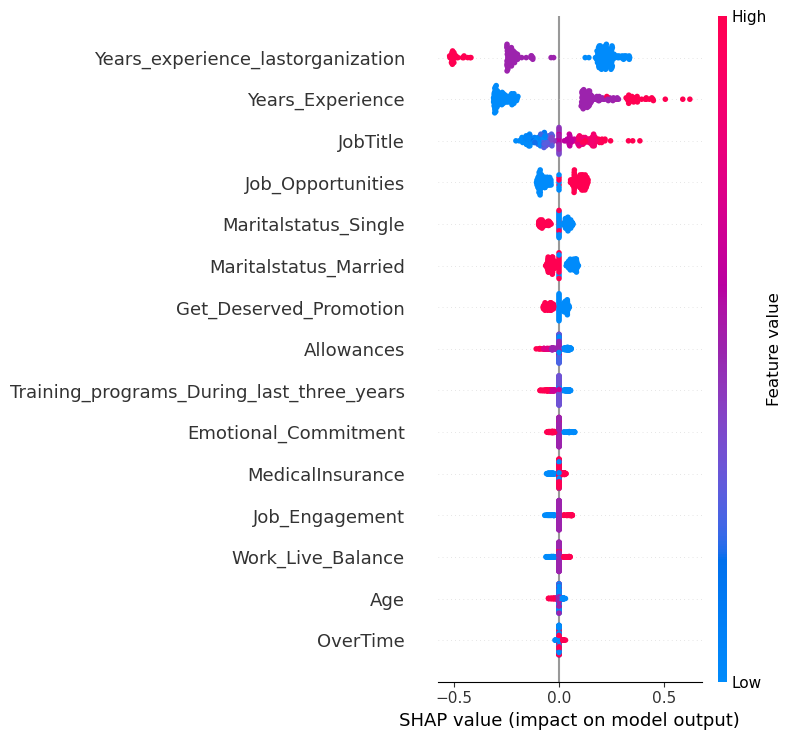

In [24]:
# ===============================================================
# SHAP QUANTITATIVE ANALYSIS — FINAL NON-TREE MODEL
# ===============================================================
#
# Uses the final model configuration selected from results_df:
#
#   StandardScaler
#        ↓
#   Feature Selection
#        ↓
#   Final Non-Tree Model
#        ↓
#   SHAP Analysis
#
# SMOTE is NOT applied to X_test.
# SHAP explains predictions on the original independent test data.
# ===============================================================

import shap


# ===============================================================
# EXTRACT FITTED PIPELINE COMPONENTS
# ===============================================================

fitted_scaler = final_pipe.named_steps["scaler"]

fitted_selector = final_pipe.named_steps["feature_selection"]

fitted_model = final_pipe.named_steps["model"]


# ===============================================================
# APPLY FITTED SCALER
# ===============================================================

X_train_scaled = fitted_scaler.transform(
    X_train
)

X_test_scaled = fitted_scaler.transform(
    X_test
)


# ===============================================================
# APPLY FITTED FEATURE SELECTION
# ===============================================================

if best_feature_set == "ALL":

    # -----------------------------------------------------------
    # All original features are used
    # -----------------------------------------------------------

    X_train_shap = X_train_scaled

    X_test_shap = X_test_scaled

    selected_feature_names = (
        X_train.columns
        .tolist()
    )


else:

    # -----------------------------------------------------------
    # Apply fitted feature selector
    # -----------------------------------------------------------

    X_train_shap = fitted_selector.transform(
        X_train_scaled
    )

    X_test_shap = fitted_selector.transform(
        X_test_scaled
    )


    # -----------------------------------------------------------
    # Obtain selected feature names
    # -----------------------------------------------------------

    selected_mask = (
        fitted_selector.get_support()
    )

    selected_feature_names = (
        X_train.columns[
            selected_mask
        ]
        .tolist()
    )


# ===============================================================
# CONVERT TO DATAFRAMES
# ===============================================================

X_train_shap_df = pd.DataFrame(
    X_train_shap,
    columns=selected_feature_names,
    index=X_train.index
)


X_test_shap_df = pd.DataFrame(
    X_test_shap,
    columns=selected_feature_names,
    index=X_test.index
)


# ===============================================================
# DISPLAY FINAL MODEL CONFIGURATION
# ===============================================================

print("=" * 80)
print("SHAP ANALYSIS CONFIGURATION — NON-TREE MODEL")
print("=" * 80)

print(f"Best Model        : {best_model_name}")
print(f"Feature Selection : {best_feature_set}")

print(
    f"Original Features : "
    f"{X_train.shape[1]}"
)

print(
    f"Features Used     : "
    f"{len(selected_feature_names)}"
)


print("\nFEATURES USED FOR SHAP")
print("-" * 80)

for i, feature in enumerate(
    selected_feature_names,
    start=1
):

    print(
        f"{i:>2}. {feature}"
    )


# ===============================================================
# CREATE SHAP BACKGROUND DATA
# ===============================================================
#
# A representative sample of training data is used as the
# background distribution.
# ===============================================================

background_size = min(
    100,
    len(X_train_shap_df)
)


background_data = shap.sample(
    X_train_shap_df,
    background_size,
    random_state=SEED
)


# ===============================================================
# CREATE MODEL-AGNOSTIC SHAP EXPLAINER
# ===============================================================
#
# KernelExplainer works with:
#
# Logistic Regression
# RBF SVM
# KNN
# Naive Bayes
# MLP
# Voting Ensemble
# Stacking Ensemble
# ===============================================================

explainer = shap.KernelExplainer(
    fitted_model.predict_proba,
    background_data
)


# ===============================================================
# COMPUTE SHAP VALUES
# ===============================================================

print("\nComputing SHAP values...")

shap_values = explainer.shap_values(
    X_test_shap_df
)


print("[OK] SHAP values computed.")


# ===============================================================
# HANDLE DIFFERENT SHAP OUTPUT FORMATS
# ===============================================================

print("\nSHAP OUTPUT DIAGNOSTICS")
print("-" * 80)


# ---------------------------------------------------------------
# CASE 1: SHAP returns a list
# Usually one array per class
# ---------------------------------------------------------------

if isinstance(shap_values, list):

    shap_values_positive = np.asarray(
        shap_values[1]
    )


# ---------------------------------------------------------------
# CASE 2: SHAP returns a 3-dimensional array
#
# Usually:
# samples × features × classes
# ---------------------------------------------------------------

else:

    shap_values_array = np.asarray(
        shap_values
    )

    if shap_values_array.ndim == 3:

        shap_values_positive = (
            shap_values_array[:, :, 1]
        )

    else:

        shap_values_positive = (
            shap_values_array
        )


print(
    "Final SHAP value shape:",
    shap_values_positive.shape
)

print(
    "Number of selected features:",
    len(selected_feature_names)
)


# ===============================================================
# VALIDATE SHAP DIMENSIONS
# ===============================================================

if shap_values_positive.ndim != 2:

    raise ValueError(
        "SHAP values must have two dimensions: "
        "(samples, features)."
    )


if (
    shap_values_positive.shape[1]
    != len(selected_feature_names)
):

    raise ValueError(
        "Mismatch between SHAP features and selected feature names."
    )


# ===============================================================
# QUANTITATIVE SHAP FEATURE IMPORTANCE
# ===============================================================
#
# Mean absolute SHAP value is used as the global importance measure.
# ===============================================================

mean_abs_shap = np.mean(
    np.abs(shap_values_positive),
    axis=0
)


# ===============================================================
# CREATE FEATURE IMPORTANCE DATAFRAME
# ===============================================================

shap_importance_df = pd.DataFrame({

    "Feature":
        selected_feature_names,

    "Mean |SHAP|":
        mean_abs_shap
})


# ===============================================================
# SORT BY GLOBAL SHAP IMPORTANCE
# ===============================================================

shap_importance_df = (
    shap_importance_df
    .sort_values(
        by="Mean |SHAP|",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)


# ===============================================================
# CALCULATE SHAP CONTRIBUTION PERCENTAGE
# ===============================================================

total_shap_importance = (
    shap_importance_df[
        "Mean |SHAP|"
    ]
    .sum()
)


shap_importance_df[
    "Relative Importance (%)"
] = (
    shap_importance_df["Mean |SHAP|"]
    /
    shap_importance_df["Mean |SHAP|"].sum()
    *
    100
)


# ===============================================================
# DISPLAY QUANTITATIVE RESULTS
# ===============================================================

print("\n" + "=" * 90)

print(
    f"SHAP QUANTITATIVE FEATURE IMPORTANCE — "
    f"{best_model_name.upper()}"
)

print("=" * 90)


print(
    shap_importance_df
    .round(4)
    .to_string(index=False)
)


# ===============================================================
# DISPLAY TOP 10 FEATURES
# ===============================================================

print("\nTOP 10 MOST IMPORTANT FEATURES")
print("=" * 90)


print(
    shap_importance_df
    .head(10)
    .round(4)
    .to_string(index=False)
)


# ===============================================================
# SHAP SUMMARY PLOT
# ===============================================================

print(
    "\nGenerating SHAP summary plot..."
)


shap.summary_plot(
    shap_values_positive,
    X_test_shap_df,
    feature_names=selected_feature_names,
    max_display=15,
    show=False
)
# Adjust layout
plt.tight_layout()

# Save at 600 DPI
plt.savefig(
    "SHAP_Summary_Plot_NonTree_Model.png",
    dpi=600,
    bbox_inches="tight"
)

# Display plot
plt.show()

# Close figure
plt.close()



ORIGINAL MODEL — QUANTILE CALIBRATION
                            bin  Mean_Predicted_Probability  Observed_Attrition_Rate  Count
(0.0034999999999999996, 0.0349]                      0.0193                   0.0000     24
               (0.0349, 0.0748]                      0.0553                   0.0435     23
                (0.0748, 0.136]                      0.1054                   0.1667     24
                 (0.136, 0.219]                      0.1730                   0.3043     23
                 (0.219, 0.337]                      0.2782                   0.2917     24
                 (0.337, 0.451]                      0.3994                   0.4783     23
                 (0.451, 0.634]                      0.5458                   0.4348     23
                 (0.634, 0.847]                      0.7640                   0.5833     24
                 (0.847, 0.985]                      0.9327                   0.9565     23
                   (0.985, 1.0]          

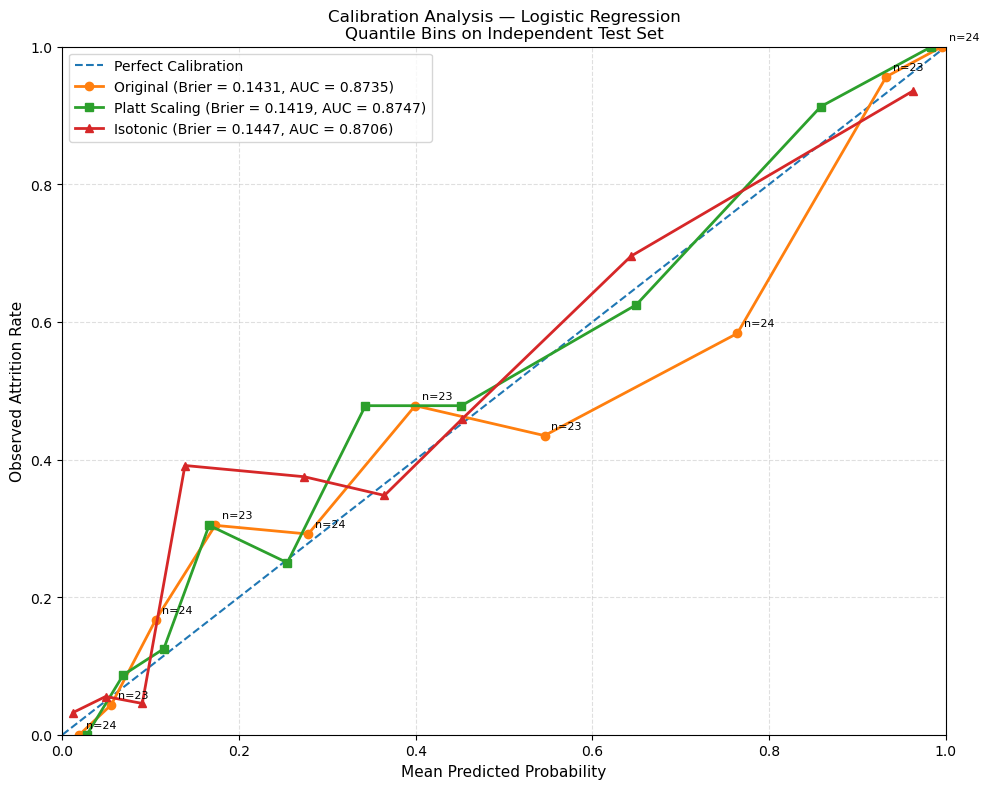

In [25]:
# ===============================================================
# CALIBRATION CURVE — QUANTILE BINS WITH SAMPLE COUNTS
# ===============================================================

def calibration_bins_with_counts(y_true, y_prob, n_bins=10):

    cal_df = pd.DataFrame({
        "y_true": np.asarray(y_true),
        "y_prob": np.asarray(y_prob)
    })

    # -----------------------------------------------------------
    # Quantile-based bins
    # -----------------------------------------------------------
    cal_df["bin"] = pd.qcut(
        cal_df["y_prob"],
        q=n_bins,
        duplicates="drop"
    )

    # -----------------------------------------------------------
    # Calculate calibration statistics
    # -----------------------------------------------------------
    calibration_table = (
        cal_df
        .groupby("bin", observed=True)
        .agg(
            Mean_Predicted_Probability=("y_prob", "mean"),
            Observed_Attrition_Rate=("y_true", "mean"),
            Count=("y_true", "size")
        )
        .reset_index()
    )

    return calibration_table


# ===============================================================
# CREATE QUANTILE CALIBRATION TABLES
# ===============================================================

cal_original = calibration_bins_with_counts(
    y_test,
    y_prob_original,
    n_bins=10
)

cal_platt = calibration_bins_with_counts(
    y_test,
    y_prob_platt,
    n_bins=10
)

cal_isotonic = calibration_bins_with_counts(
    y_test,
    y_prob_isotonic,
    n_bins=10
)


# ===============================================================
# DISPLAY CALIBRATION TABLES
# ===============================================================

print("\nORIGINAL MODEL — QUANTILE CALIBRATION")
print("=" * 70)
print(cal_original.round(4).to_string(index=False))

print("\nPLATT CALIBRATION — QUANTILE CALIBRATION")
print("=" * 70)
print(cal_platt.round(4).to_string(index=False))

print("\nISOTONIC CALIBRATION — QUANTILE CALIBRATION")
print("=" * 70)
print(cal_isotonic.round(4).to_string(index=False))


# ===============================================================
# CALIBRATION PLOT
# ===============================================================

plt.figure(figsize=(10, 8))

# ---------------------------------------------------------------
# Perfect calibration
# ---------------------------------------------------------------

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Perfect Calibration"
)


# ---------------------------------------------------------------
# Original model
# ---------------------------------------------------------------

plt.plot(
    cal_original["Mean_Predicted_Probability"],
    cal_original["Observed_Attrition_Rate"],
    marker="o",
    linewidth=2,
    label=(
        f"Original "
        f"(Brier = {brier_original:.4f}, "
        f"AUC = {roc_original:.4f})"
    )
)


# ---------------------------------------------------------------
# Annotate original counts
# ---------------------------------------------------------------

for _, row in cal_original.iterrows():

    plt.annotate(
        f"n={int(row['Count'])}",
        (
            row["Mean_Predicted_Probability"],
            row["Observed_Attrition_Rate"]
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )


# ---------------------------------------------------------------
# Platt scaling
# ---------------------------------------------------------------

plt.plot(
    cal_platt["Mean_Predicted_Probability"],
    cal_platt["Observed_Attrition_Rate"],
    marker="s",
    linewidth=2,
    label=(
        f"Platt Scaling "
        f"(Brier = {brier_platt:.4f}, "
        f"AUC = {roc_platt:.4f})"
    )
)


# ---------------------------------------------------------------
# Isotonic regression
# ---------------------------------------------------------------

plt.plot(
    cal_isotonic["Mean_Predicted_Probability"],
    cal_isotonic["Observed_Attrition_Rate"],
    marker="^",
    linewidth=2,
    label=(
        f"Isotonic "
        f"(Brier = {brier_isotonic:.4f}, "
        f"AUC = {roc_isotonic:.4f})"
    )
)


# ===============================================================
# AXIS LABELS AND TITLE
# ===============================================================

plt.xlabel(
    "Mean Predicted Probability",
    fontsize=11
)

plt.ylabel(
    "Observed Attrition Rate",
    fontsize=11
)

plt.title(
    f"Calibration Analysis — {best_model_name}\n"
    "Quantile Bins on Independent Test Set",
    fontsize=12
)

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.grid(
    True,
    linestyle="--",
    alpha=0.4
)

plt.legend(
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    "Calibration_Quantile_Bins.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()